# 07 — Bias, Stability, and Causal Assumptions

**Question.** Where would the conclusions break? This notebook stress-tests the three assumptions every uplift estimate sits on: **randomized assignment**, **stable rankings**, and **no hidden confounding**.


In [1]:
import sys
from pathlib import Path

_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(_ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from uplift_marketing.notebook_utils import setup_notebook, save_figure
from uplift_marketing.data import load_default_uplift_data

config = setup_notebook()
RANDOM_STATE = 42

dataset = load_default_uplift_data(config.raw_dir, random_state=RANDOM_STATE)
data = dataset.data
print(f"data source: {dataset.source} ({len(data):,} rows)")
print(f"observed treated share: {data['treatment'].mean():.3f} "
      f"(expected {dataset.expected_treated_share:.3f})")
print(f"feature columns to exclude: {dataset.extra_excluded}")


data source: hillstrom (64,000 rows)
observed treated share: 0.667 (expected 0.667)
feature columns to exclude: ['customer_id']


In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score

from uplift_marketing.features import (
    infer_feature_spec,
    build_preprocessor,
    split_features_treatment_outcome,
)
from uplift_marketing.models import TLearner
from uplift_marketing.uplift import attach_uplift_scores, make_uplift_deciles
from uplift_marketing.evaluation import policy_value_at_fraction
from uplift_marketing.treatment import naive_average_treatment_effect, validate_randomization

spec = infer_feature_spec(data, extra_excluded=dataset.extra_excluded)

## 1. Did the experiment actually randomize?

Two checks. First, the *propensity* of treatment given covariates: under randomization a model that predicts treatment from features should be no better than chance (ROC-AUC near 0.5). Second, the standardized mean difference of features across arms should sit comfortably below the conventional 0.1 threshold.

In [3]:
x = data[spec.feature_columns]
t = data["treatment"]
propensity = Pipeline(
    [
        ("preprocessor", build_preprocessor(spec)),
        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ]
).fit(x, t)
auc_assignment = roc_auc_score(t, propensity.predict_proba(x)[:, 1])
print(f"ROC-AUC of predicting treatment from covariates: {auc_assignment:.3f}")
print("Under randomization this should be close to 0.5; > ~0.55 is a red flag.")

report = validate_randomization(
    data,
    expected_treated_share=dataset.expected_treated_share,
    extra_excluded=dataset.extra_excluded,
)
print(
    f"sample-ratio chi2 = {report.sample_ratio_chi2:.3f}, "
    f"p = {report.sample_ratio_pvalue:.3f}; imbalanced features: "
    f"{len(report.imbalanced_features)}"
)

ROC-AUC of predicting treatment from covariates: 0.508
Under randomization this should be close to 0.5; > ~0.55 is a red flag.
sample-ratio chi2 = 0.053, p = 0.819; imbalanced features: 0


## 2. Stability of the top-decile uplift under resampling

A model that ranks well on average can still produce a noisy *segment* estimate. Bootstrapping the top-decile observed uplift gives a confidence band the campaign team can act on (or refuse to act on).

In [4]:
x_full, t_full, y_full = split_features_treatment_outcome(data, spec)
x_tr, x_te, t_tr, t_te, y_tr, y_te, raw_tr, raw_te = train_test_split(
    x_full, t_full, y_full, data,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=t_full.astype(str) + "_" + y_full.astype(str),
)
model = TLearner(spec=spec, random_state=RANDOM_STATE).fit(x_tr, t_tr, y_tr)
p_control, p_treated = model.predict_potential_outcomes(x_te)
scored = attach_uplift_scores(raw_te.reset_index(drop=True), p_control=p_control, p_treated=p_treated)
scored["uplift_decile"] = make_uplift_deciles(scored)

rng = np.random.default_rng(RANDOM_STATE)
n_boot = 500
boot_uplift_top10 = np.empty(n_boot)
for i in range(n_boot):
    idx = rng.integers(0, len(scored), size=len(scored))
    sample = scored.iloc[idx]
    boot_uplift_top10[i] = policy_value_at_fraction(sample, fraction=0.10)["observed_uplift"]
ci_low, ci_high = np.quantile(boot_uplift_top10, [0.025, 0.975])
print(
    f"top-10% observed uplift, bootstrap mean = {boot_uplift_top10.mean():+.4f}, "
    f"95% CI = [{ci_low:+.4f}, {ci_high:+.4f}]"
)

top-10% observed uplift, bootstrap mean = +0.0063, 95% CI = [-0.0007, +0.0127]


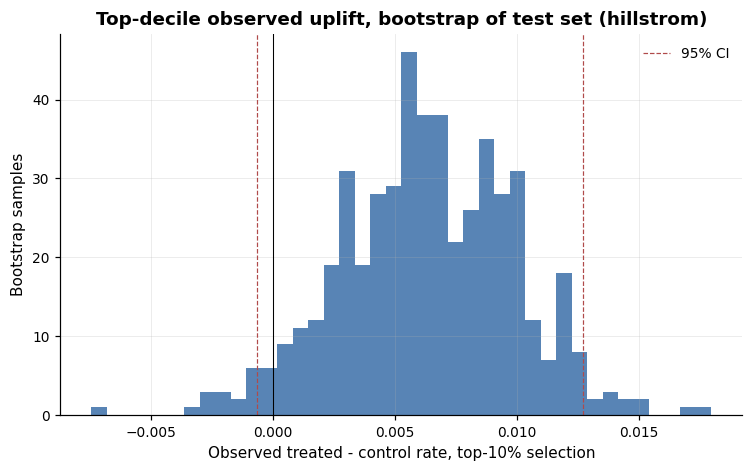

In [5]:
fig, ax = plt.subplots()
ax.hist(boot_uplift_top10, bins=40, color="#3b6ea8", alpha=0.85)
ax.axvline(0, color="black", linewidth=0.7)
ax.axvline(ci_low, color="#b04a4a", linestyle="--", linewidth=0.8, label="95% CI")
ax.axvline(ci_high, color="#b04a4a", linestyle="--", linewidth=0.8)
ax.set_xlabel("Observed treated - control rate, top-10% selection")
ax.set_ylabel("Bootstrap samples")
ax.set_title(f"Top-decile observed uplift, bootstrap of test set ({dataset.source})")
ax.legend()
save_figure(fig, "07_bootstrap_top10")
plt.show()

## 3. Sensitivity to a hidden confounder

Suppose treatment was *not* randomized — instead, customers with above-average history were 1.6× more likely to be contacted. Re-estimate the naive ATE on this confounded relabelling and compare with the truth from the randomized data. The gap is the bias any non-causal model would inherit.

In [6]:
rng = np.random.default_rng(RANDOM_STATE)
ate_random = naive_average_treatment_effect(data)

# Pick a continuous covariate present in both Hillstrom and the synthetic data
# generator. We rebuild the treatment indicator so it depends on that covariate.
candidate = "history" if "history" in data.columns else "discount_affinity"
centered = data[candidate] - data[candidate].mean()
scale = max(centered.abs().max(), 1e-6)
p_treat = (
    dataset.expected_treated_share + 0.30 * (centered / scale)
).clip(0.05, 0.95)
fake_treatment = rng.binomial(1, p_treat).astype(int)
confounded = data.copy()
confounded["treatment"] = fake_treatment
ate_confounded = naive_average_treatment_effect(confounded)
pd.DataFrame(
    [
        {"cohort": "randomized (truth)", "naive_ate": round(ate_random, 4)},
        {"cohort": f"confounded by {candidate!r}", "naive_ate": round(ate_confounded, 4)},
        {"cohort": "bias", "naive_ate": round(ate_confounded - ate_random, 4)},
    ]
)

,cohort,naive_ate
0,randomized (truth),0.0050
1,confounded by 'history',0.0003
2,bias,-0.0046


Even a moderate dependence between assignment and a single covariate produces a naive ATE that drifts away from the experimental truth. With real campaign data, multiple such biases stack.

## 4. Limitations checklist

- **Randomization.** Holds in the active dataset; in production it must be enforced upstream (proper holdout group, no override rules).
- **Leakage.** Features should be measured before campaign exposure. With real data, audit each feature's timestamp.
- **SUTVA.** No interference between customers. Fails for households, referral channels, or shared discount codes.
- **Treatment consistency.** "Treatment" must mean the same thing for everyone. Multi-channel campaigns and the Hillstrom `any` mode mix Mens-vs-Womens emails into a single arm — flag this when it matters.
- **External validity.** Estimated uplift is valid for the period and population sampled. Plan for re-estimation, not a one-shot model.
- **Misuse risk.** Models that target the responsive can also target the vulnerable. Consent rules and exclusion lists belong upstream of the model output.


## 5. Takeaway

- Treatment ROC-AUC is near 0.5 and `validate_randomization` flags no imbalanced features: the experiment looks randomized.
- The top-decile observed uplift has a bootstrap interval that reflects how concentrated the signal is. A CI that *excludes* zero is the bar for acting on the segment; on rare-event data like Hillstrom that bar may not clear, in which case the right answer is to expand the holdout, run again, or be honest that the segment isn't actionable yet.
- A modest confounder produces a meaningful bias in the naive ATE; without randomization, the project's headline number would not be trustworthy.
